а) 6 красных, без возвращения: теория = 0.000832120; эксперимент = 0.000865000
б) 3 синих, 2 белых, 1 красный: теория = 0.049927190; эксперимент = 0.049978000
в) ровно 4 белых: теория = 0.072810485; эксперимент = 0.072490000
г) 6 красных, с возвращением: теория = 0.003589947; эксперимент = 0.003566000


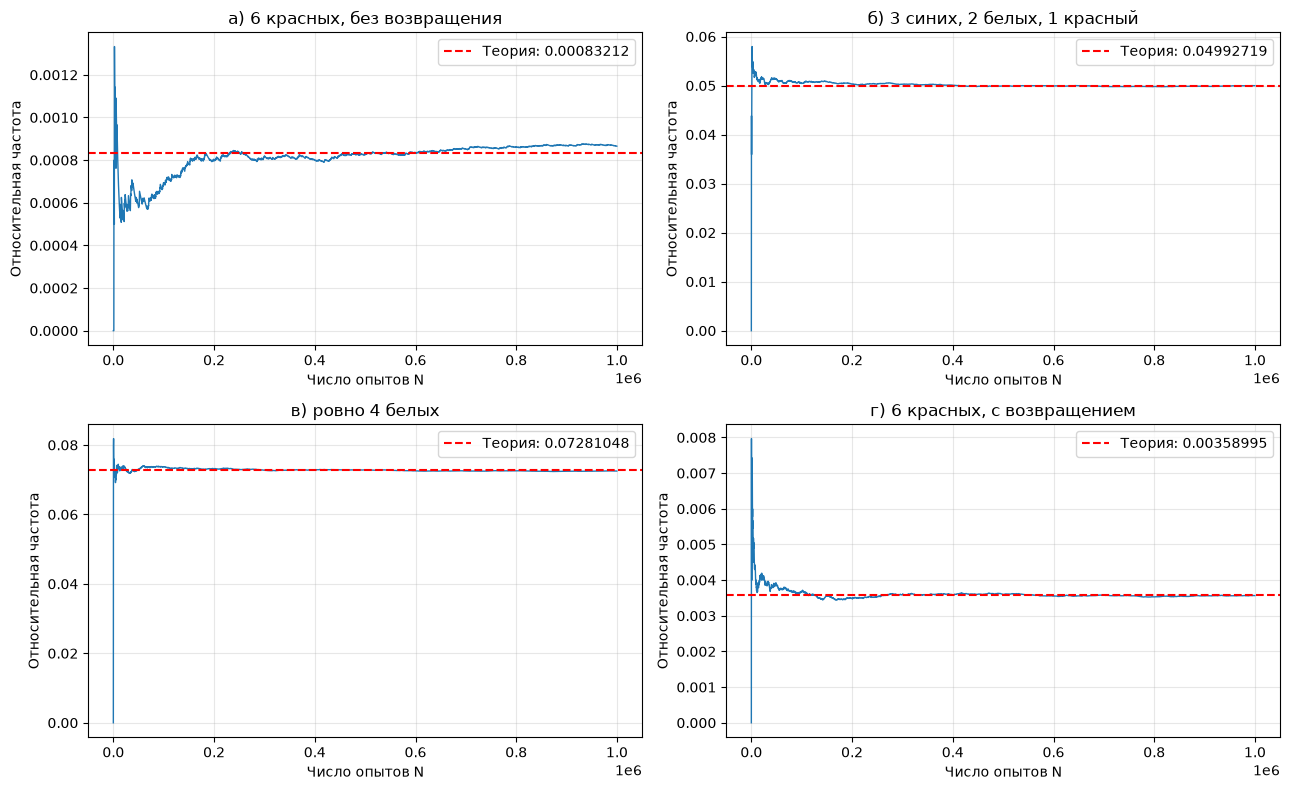

In [1]:
# 4.1
import numpy as np
import matplotlib.pyplot as plt
from math import comb

rng = np.random.default_rng(41)
N = 1_000_000
without = rng.multivariate_hypergeometric([8, 6, 9], 6, size=N)
A = without[:, 2] == 6
B = (without[:, 1] == 3) & (without[:, 0] == 2) & (without[:, 2] == 1)
D = without[:, 0] == 4
with_replacement = rng.multinomial(6, [8/23, 6/23, 9/23], size=N)
A_replacement = with_replacement[:, 2] == 6
probs = {
    'а) 6 красных, без возвращения': (A, comb(9, 6)/comb(23, 6)),
    'б) 3 синих, 2 белых, 1 красный': (B, comb(6, 3)*comb(8, 2)*comb(9, 1)/comb(23, 6)),
    'в) ровно 4 белых': (D, comb(8, 4)*comb(15, 2)/comb(23, 6)),
    'г) 6 красных, с возвращением': (A_replacement, (9/23)**6),
}
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (name, (event, exact)) in zip(axes.flat, probs.items()):
    count = np.cumsum(event)
    n = np.arange(1, N+1)
    ax.plot(n[::250], (count/n)[::250], lw=1)
    ax.axhline(exact, color='red', linestyle='--', label=f'Теория: {exact:.8f}')
    ax.set_title(name)
    ax.set_xlabel('Число опытов N')
    ax.set_ylabel('Относительная частота')
    ax.legend()
    ax.grid(alpha=0.3)
    print(f'{name}: теория = {exact:.9f}; эксперимент = {event.mean():.9f}')
plt.tight_layout()
plt.show()

P(A) = 6/C(10,5) = 0.02380952; эксперимент = 0.02355333
P(B) = 6/C(10,5) = 0.02380952; эксперимент = 0.02394000


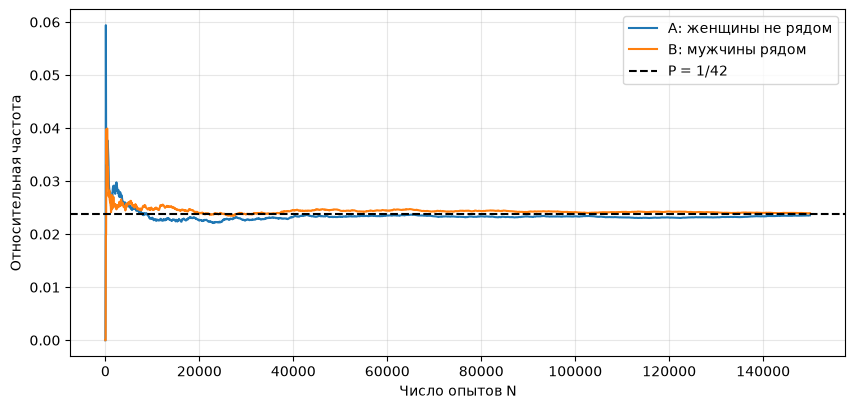

In [2]:
# 4.2
import numpy as np
import matplotlib.pyplot as plt
from math import comb

rng = np.random.default_rng(42)
N = 150_000
ranking = np.argsort(rng.random((N, 10)), axis=1)
women = np.sort(ranking[:, :5], axis=1)
men = np.sort(ranking[:, 5:], axis=1)
A = np.all(np.diff(women, axis=1) > 1, axis=1)
B = np.all(np.diff(men, axis=1) == 1, axis=1)
p = 1/42
print(f'P(A) = 6/C(10,5) = {p:.8f}; эксперимент = {A.mean():.8f}')
print(f'P(B) = 6/C(10,5) = {p:.8f}; эксперимент = {B.mean():.8f}')
n = np.arange(1, N+1)
plt.figure(figsize=(10, 4.5))
plt.plot(n[::50], (A.cumsum()/n)[::50], label='A: женщины не рядом')
plt.plot(n[::50], (B.cumsum()/n)[::50], label='B: мужчины рядом')
plt.axhline(p, color='black', linestyle='--', label='P = 1/42')
plt.xlabel('Число опытов N')
plt.ylabel('Относительная частота')
plt.grid(alpha=.3)
plt.legend()
plt.show()

P(T ≤ 5) = 0.96875000; эксперимент = 0.96904000


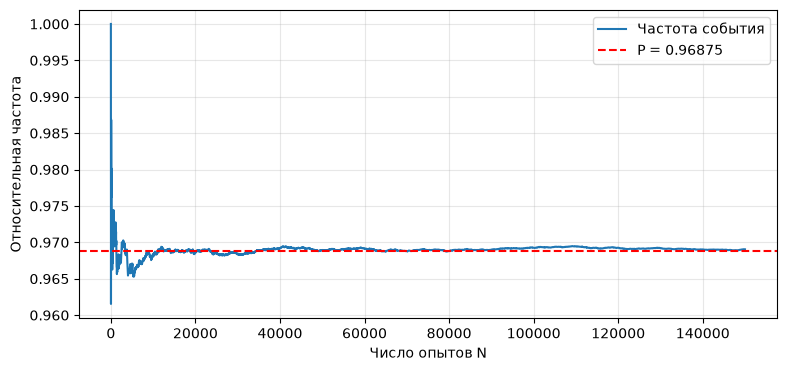

In [3]:
# 4.3
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(43)
N = 150_000
throws = rng.geometric(0.5, size=N)
A = throws <= 5
p = 1 - (1/2)**5
print(f'P(T ≤ 5) = {p:.8f}; эксперимент = {A.mean():.8f}')
n = np.arange(1, N+1)
plt.figure(figsize=(9, 4))
plt.plot(n[::25], (A.cumsum()/n)[::25], label='Частота события')
plt.axhline(p, color='red', linestyle='--', label=f'P = {p}')
plt.xlabel('Число опытов N')
plt.ylabel('Относительная частота')
plt.legend()
plt.grid(alpha=.3)
plt.show()

P(T = k) = 1/2^(k-1), k ≥ 2
P(T чётно) = 2/3 = 0.66666667; эксперимент = 0.66809333


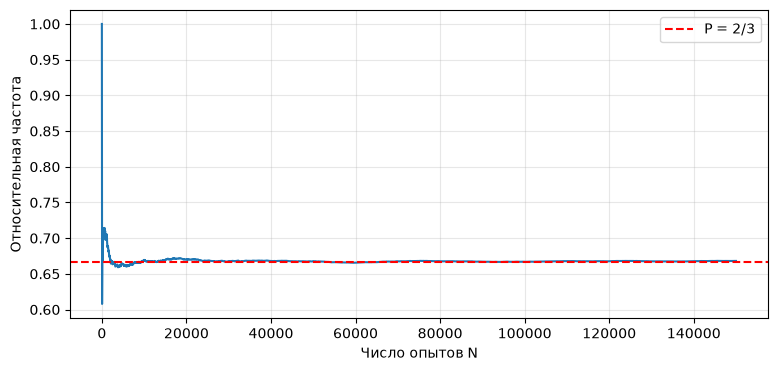

In [4]:
# 4.4
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(44)
N = 150_000
T = rng.geometric(0.5, size=N) + 1
A = T % 2 == 0
p = 2/3
print('P(T = k) = 1/2^(k-1), k ≥ 2')
print(f'P(T чётно) = 2/3 = {p:.8f}; эксперимент = {A.mean():.8f}')
n = np.arange(1, N+1)
plt.figure(figsize=(9, 4))
plt.plot(n[::25], (A.cumsum()/n)[::25])
plt.axhline(p, color='red', linestyle='--', label='P = 2/3')
plt.xlabel('Число опытов N')
plt.ylabel('Относительная частота')
plt.legend()
plt.grid(alpha=.3)
plt.show()

а) P(чётно) = 0.73417722; эксперимент = 0.73308667


б) P(кратно 4) = 0.12741919; эксперимент = 0.12737333


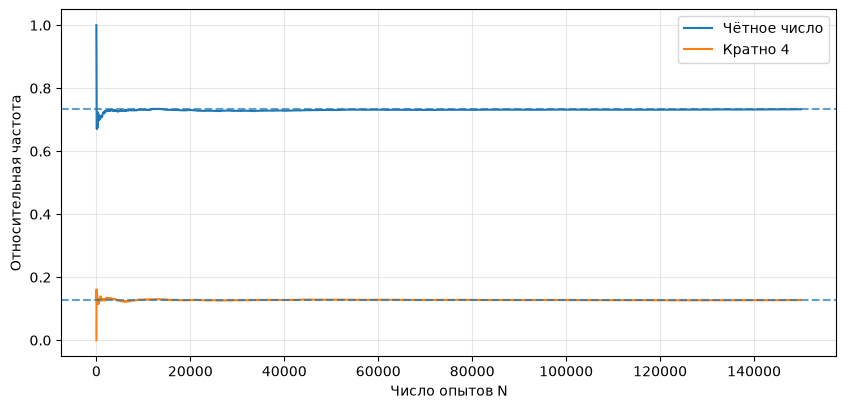

In [5]:
# 4.5
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(45)
N = 150_000
p = 0.7
q = 1-p
previous = rng.random(N) < p
T = np.ones(N, dtype=int)
active = np.ones(N, dtype=bool)
while np.any(active):
    idx = np.flatnonzero(active)
    current = rng.random(idx.size) < p
    T[idx] += 1
    stopped = current == previous[idx]
    active[idx[stopped]] = False
    previous[idx[~stopped]] = current[~stopped]
A = T % 2 == 0
B = T % 4 == 0
pA = (p*p+q*q)/(1-p*q)
pB = p*q*(p*p+q*q)/(1-(p*q)**2)
print(f'а) P(чётно) = {pA:.8f}; эксперимент = {A.mean():.8f}')
print(f'б) P(кратно 4) = {pB:.8f}; эксперимент = {B.mean():.8f}')
n = np.arange(1, N+1)
plt.figure(figsize=(10, 4.5))
for event, label, exact in [(A, 'Чётное число', pA), (B, 'Кратно 4', pB)]:
    plt.plot(n[::30], (event.cumsum()/n)[::30], label=label)
    plt.axhline(exact, linestyle='--', alpha=.7)
plt.xlabel('Число опытов N')
plt.ylabel('Относительная частота')
plt.legend()
plt.grid(alpha=.3)
plt.show()

P(встреча) = 0.332777778; оценка при N=150000: 0.331600000


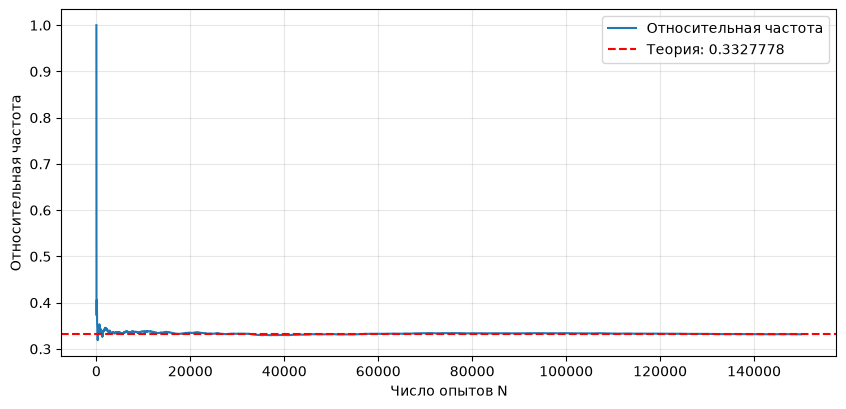

In [6]:
# 4.6
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(46)
N = 150_000
A_time = rng.uniform(0, 60, N)
B_time = rng.uniform(0, 60, N)
met = ((A_time <= B_time) & (B_time-A_time <= 10)) | ((B_time < A_time) & (A_time-B_time <= 12))
p = (60*10-10**2/2 + 60*12-12**2/2) / 60**2
print(f'P(встреча) = {p:.9f}; оценка при N={N}: {met.mean():.9f}')
n = np.arange(1, N+1)
plt.figure(figsize=(10, 4.5))
plt.plot(n[::25], (met.cumsum()/n)[::25], label='Относительная частота')
plt.axhline(p, color='red', linestyle='--', label=f'Теория: {p:.7f}')
plt.xlabel('Число опытов N')
plt.ylabel('Относительная частота')
plt.legend()
plt.grid(alpha=.3)
plt.show()

C: Иван пришёл вторым и встретил Петра, поэтому не ждал.
E: Иван пришёл после того, как Пётр уже ушёл.
Если под «опоздал» понимать просто приход вторым, вероятность 1/2.
A: теория = 0.43750000, эксперимент = 0.43714000
B: теория = 0.56250000, эксперимент = 0.56286000
C: теория = 0.21875000, эксперимент = 0.21831333
D: теория = 0.25000000, эксперимент = 0.25066667
E: теория = 0.28125000, эксперимент = 0.28212000
F: теория = 0.04166667, эксперимент = 0.04180000


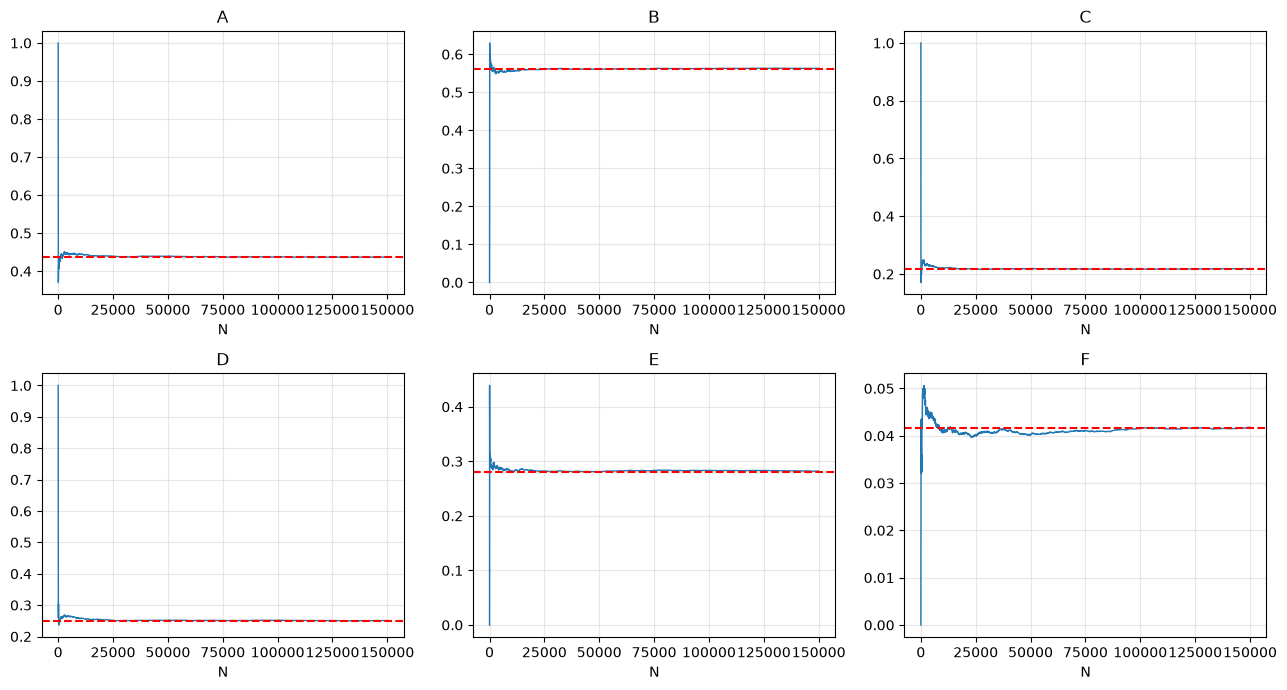

In [7]:
# 4.7
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(47)
N = 150_000
ivan = rng.uniform(0, 60, N)
petr = rng.uniform(0, 60, N)
A = np.abs(ivan-petr) <= 15
B = ~A
C = A & (ivan >= petr)
D = A & (np.maximum(ivan, petr) > 30)
E = ivan > petr+15
F = A & (np.maximum(ivan, petr) > 55)
experiments = {'A': A, 'B': B, 'C': C, 'D': D, 'E': E, 'F': F}
theory = {'A': 7/16, 'B': 9/16, 'C': 7/32, 'D': 1/4, 'E': 9/32, 'F': 1/24}
print('C: Иван пришёл вторым и встретил Петра, поэтому не ждал.')
print('E: Иван пришёл после того, как Пётр уже ушёл.')
print('Если под «опоздал» понимать просто приход вторым, вероятность 1/2.')
for key, event in experiments.items():
    print(f'{key}: теория = {theory[key]:.8f}, эксперимент = {event.mean():.8f}')
n = np.arange(1, N+1)
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (key, event) in zip(axes.flat, experiments.items()):
    ax.plot(n[::40], (event.cumsum()/n)[::40], lw=1)
    ax.axhline(theory[key], color='red', linestyle='--')
    ax.set_title(key)
    ax.set_xlabel('N')
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

A: теория = 0.30685282, эксперимент = 0.30744667
B: теория = 0.84657359, эксперимент = 0.84756667
C: теория = 0.69314718, эксперимент = 0.69306000


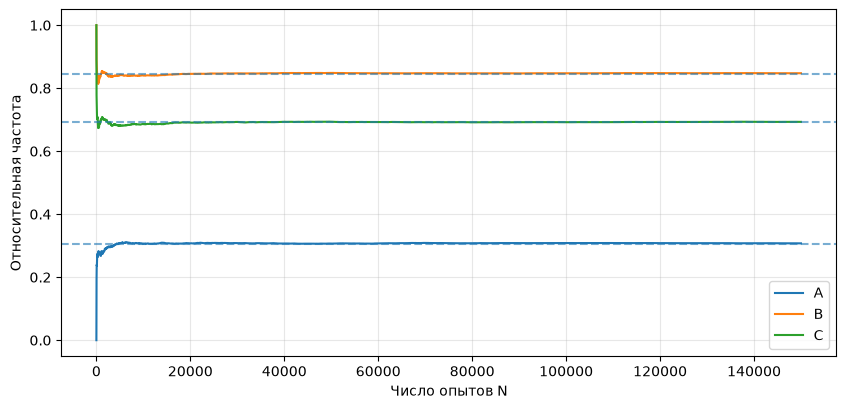

In [8]:
# 4.8
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(48)
N = 150_000
x = rng.random(N)
y = x*rng.random(N)
A = 1-y < x
B = x-y < 0.5
C = x-y < 1-x
theory = {'A': 1-np.log(2), 'B': (1+np.log(2))/2, 'C': np.log(2)}
events = {'A': A, 'B': B, 'C': C}
for k, e in events.items():
    print(f'{k}: теория = {theory[k]:.8f}, эксперимент = {e.mean():.8f}')
n = np.arange(1, N+1)
plt.figure(figsize=(10, 4.5))
for k, e in events.items():
    plt.plot(n[::35], (e.cumsum()/n)[::35], label=k)
    plt.axhline(theory[k], linestyle='--', alpha=.6)
plt.xlabel('Число опытов N')
plt.ylabel('Относительная частота')
plt.legend()
plt.grid(alpha=.3)
plt.show()

P(остроугольный треугольник) = 3 ln(2) - 2 = 0.0794415417
Эксперимент N=150000: 0.0796466667


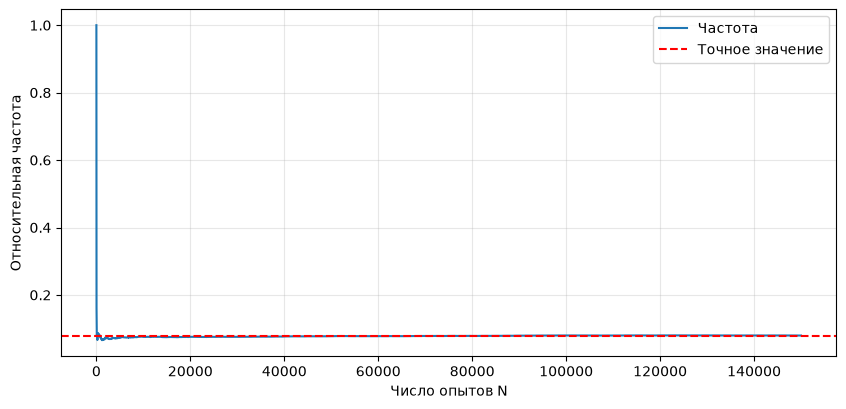

In [9]:
# 4.9
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(49)
N = 150_000
cuts = np.sort(rng.random((N, 2)), axis=1)
a = cuts[:, 0]
b = cuts[:, 1]-cuts[:, 0]
c = 1-cuts[:, 1]
sides = np.stack((a, b, c), axis=1)
longest = sides.max(axis=1)
acute = (longest < 0.5) & (2*longest**2 < np.sum(sides**2, axis=1))
p = 3*np.log(2)-2
print(f'P(остроугольный треугольник) = 3 ln(2) - 2 = {p:.10f}')
print(f'Эксперимент N={N}: {acute.mean():.10f}')
n = np.arange(1, N+1)
plt.figure(figsize=(10, 4.5))
plt.plot(n[::30], (acute.cumsum()/n)[::30], label='Частота')
plt.axhline(p, color='red', linestyle='--', label='Точное значение')
plt.xlabel('Число опытов N')
plt.ylabel('Относительная частота')
plt.legend()
plt.grid(alpha=.3)
plt.show()

Модель: концы отрезка независимо и равномерно выбираются внутри круга.
P(длина < 1) = 0.586503328; эксперимент = 0.586700000
Без способа случайного выбора отрезка вероятность не однозначна.


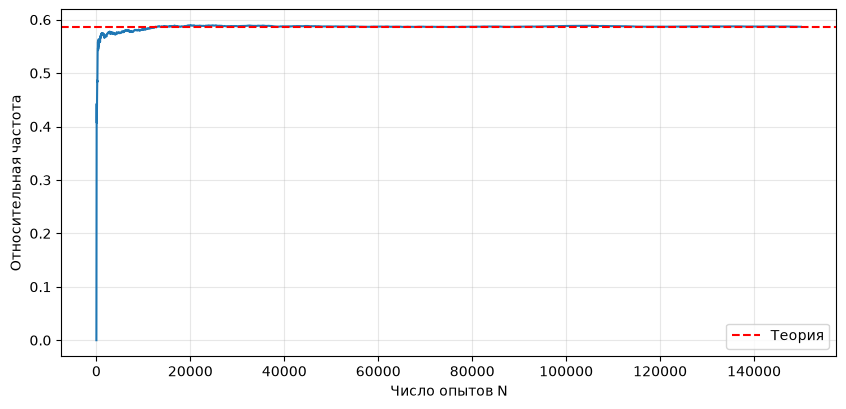

In [10]:
# 4.10
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(410)
N = 150_000
r1 = np.sqrt(rng.random(N))
r2 = np.sqrt(rng.random(N))
a1 = rng.uniform(0, 2*np.pi, N)
a2 = rng.uniform(0, 2*np.pi, N)
x1, y1 = r1*np.cos(a1), r1*np.sin(a1)
x2, y2 = r2*np.cos(a2), r2*np.sin(a2)
A = np.hypot(x1-x2, y1-y2) < 1
p = 1 - 3*np.sqrt(3)/(4*np.pi)
print('Модель: концы отрезка независимо и равномерно выбираются внутри круга.')
print(f'P(длина < 1) = {p:.9f}; эксперимент = {A.mean():.9f}')
print('Без способа случайного выбора отрезка вероятность не однозначна.')
n = np.arange(1, N+1)
plt.figure(figsize=(10, 4.5))
plt.plot(n[::30], (A.cumsum()/n)[::30])
plt.axhline(p, color='red', linestyle='--', label='Теория')
plt.xlabel('Число опытов N')
plt.ylabel('Относительная частота')
plt.legend()
plt.grid(alpha=.3)
plt.show()

P_n = n*q^(n-1) - (n-1)*q^n
n=2: -q**2 + 2*q
n=3: -2*q**3 + 3*q**2
P(хотя бы двое встретятся) = 1 - max(1-2q, 0)^3
n=2: теория = 0.43750000; эксперимент = 0.43576000
n=3: теория = 0.15625000; эксперимент = 0.15487333
Хотя бы двое: теория = 0.87500000; эксперимент = 0.87458667


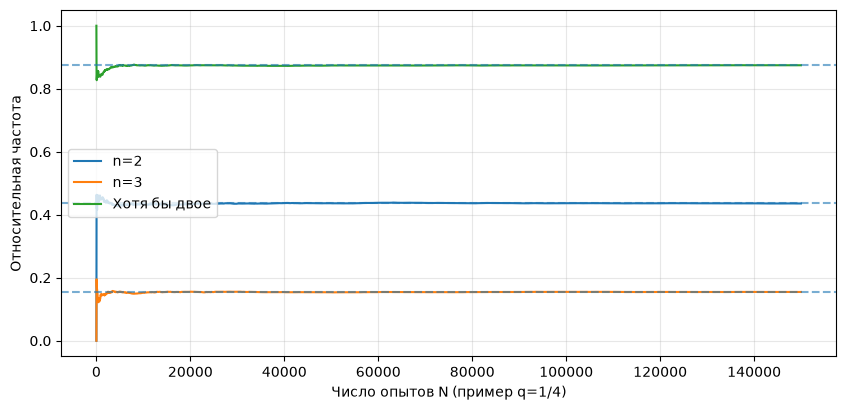

In [11]:
# 4.11
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

q = sp.symbols('q', nonnegative=True)
P2 = sp.expand(2*q-q**2)
P3 = sp.expand(3*q**2-2*q**3)
print('P_n = n*q^(n-1) - (n-1)*q^n')
print('n=2:', P2)
print('n=3:', P3)
print('P(хотя бы двое встретятся) = 1 - max(1-2q, 0)^3')
q0 = 1/4
N = 150_000
rng = np.random.default_rng(411)
two = rng.random((N, 2))
three = rng.random((N, 3))
A2 = np.ptp(two, axis=1) <= q0
A3 = np.ptp(three, axis=1) <= q0
sorted_three = np.sort(three, axis=1)
any_two = np.any(np.diff(sorted_three, axis=1) <= q0, axis=1)
theory = {'n=2': 2*q0-q0*q0, 'n=3': 3*q0*q0-2*q0**3,
          'Хотя бы двое': 1-max(1-2*q0, 0)**3}
events = {'n=2': A2, 'n=3': A3, 'Хотя бы двое': any_two}
for k, v in events.items():
    print(f'{k}: теория = {theory[k]:.8f}; эксперимент = {v.mean():.8f}')
n = np.arange(1, N+1)
plt.figure(figsize=(10, 4.5))
for k, v in events.items():
    plt.plot(n[::40], (v.cumsum()/n)[::40], label=k)
    plt.axhline(theory[k], linestyle='--', alpha=.6)
plt.xlabel('Число опытов N (пример q=1/4)')
plt.ylabel('Относительная частота')
plt.legend()
plt.grid(alpha=.3)
plt.show()

а) P2 = -w1**2/2 + w1 - w2**2/2 + w2
б) P3 = -w1**3/3 - w1*w2**2/2 + w1*w2 - w1*w3**2/2 + w1*w3 - w2**3/6 - w2*w3**2/2 + w2*w3
г) P4 = -w1**4/4 - w1*w2**3/3 - w1*w2*w3**2/2 + w1*w2*w3 - w1*w2*w4**2/2 + w1*w2*w4 - w1*w3**3/6 - w1*w3*w4**2/2 + w1*w3*w4 - w2**4/12 - w2*w3**3/6 - w2*w3*w4**2/2 + w2*w3*w4
Формулы P3 и P4 применяются для упорядоченных w1 ≤ w2 ≤ w3 ≤ w4.
в) P3 = 1435/5184 ≈ 0.2768132716049383
в) Монте-Карло: 0.27566000
г) Пример w=[0.12, 0.17, 0.23, 0.3]: теория=0.02545689, Монте-Карло=0.02498667


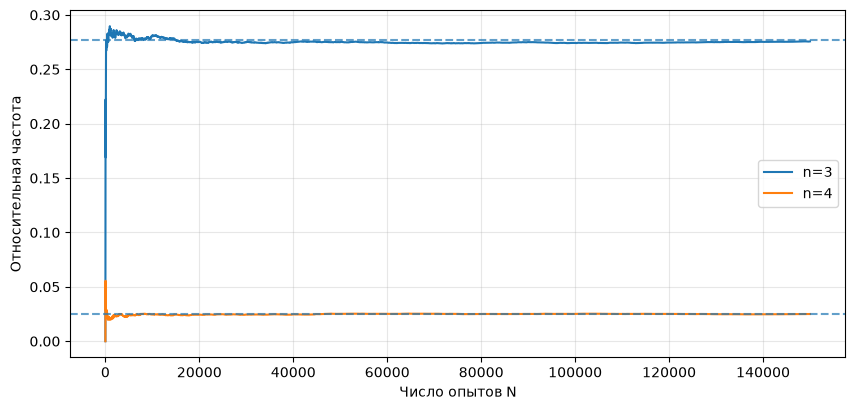

In [12]:
# 4.12
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

w1, w2, w3, w4 = sp.symbols('w1 w2 w3 w4', nonnegative=True)
P2 = sp.expand(1 - (1-w1)**2/2 - (1-w2)**2/2)
P3 = sp.expand(w1*w2+w1*w3+w2*w3 - (w1*w2**2+w1*w3**2+w2*w3**2)/2 - w1**3/3 - w2**3/6)
P4 = sp.expand(w1*w2*w3+w1*w2*w4+w1*w3*w4+w2*w3*w4 - w4**2*(w1*w2+w1*w3+w2*w3)/2 - w3**3*(w1+w2)/6 - w1*w2*w3**2/2 - w1*w2**3/3 - w1**4/4 - w2**4/12)
print('а) P2 =', P2)
print('б) P3 =', P3)
print('г) P4 =', P4)
print('Формулы P3 и P4 применяются для упорядоченных w1 ≤ w2 ≤ w3 ≤ w4.')
ws3 = [sp.Rational(1,4), sp.Rational(1,3), sp.Rational(1,2)]
answer3 = sp.factor(P3.subs(dict(zip((w1,w2,w3),ws3))))
print('в) P3 =', answer3, '≈', float(answer3))
ws4 = [.12, .17, .23, .30]
answer4 = float(P4.subs(dict(zip((w1,w2,w3,w4),ws4))))
N = 150_000
rng = np.random.default_rng(412)

def simulate(ws):
    times = rng.random((N, len(ws)))
    event = times.max(axis=1) <= np.min(times+np.array(ws), axis=1)
    return event

C = simulate([float(w) for w in ws3])
D = simulate(ws4)
print(f'в) Монте-Карло: {C.mean():.8f}')
print(f'г) Пример w={ws4}: теория={answer4:.8f}, Монте-Карло={D.mean():.8f}')
n = np.arange(1, N+1)
plt.figure(figsize=(10,4.5))
plt.plot(n[::35], (C.cumsum()/n)[::35], label='n=3')
plt.plot(n[::35], (D.cumsum()/n)[::35], label='n=4')
plt.axhline(float(answer3), linestyle='--', alpha=.7)
plt.axhline(answer4, linestyle='--', alpha=.7)
plt.xlabel('Число опытов N')
plt.ylabel('Относительная частота')
plt.legend()
plt.grid(alpha=.3)
plt.show()

Общая формула: P(белый) = (n*p + 1)/(n + 1)
При n=10, p=1/3: P = 13/33 ≈ 0.39393939; эксперимент = 0.39422667
В PDF напечатано 0.15625; оно не согласуется с указанными n=10 и p=1/3.


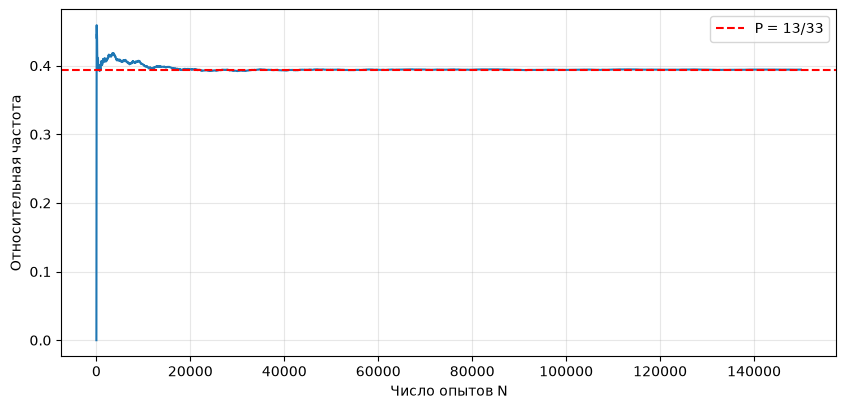

In [13]:
# 4.13
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

n = sp.symbols('n', integer=True, positive=True)
p = sp.symbols('p', real=True, nonnegative=True)
formula = (n*p+1)/(n+1)
print('Общая формула: P(белый) =', formula)
n0, p0 = 10, 1/3
exact = (n0*p0+1)/(n0+1)
N = 150_000
rng = np.random.default_rng(413)
white_initial = rng.binomial(n0, p0, size=N)
A = rng.integers(0, n0+1, size=N) < (white_initial+1)
print(f'При n=10, p=1/3: P = 13/33 ≈ {exact:.8f}; эксперимент = {A.mean():.8f}')
print('В PDF напечатано 0.15625; оно не согласуется с указанными n=10 и p=1/3.')
n_values = np.arange(1, N+1)
plt.figure(figsize=(10,4.5))
plt.plot(n_values[::30], (A.cumsum()/n_values)[::30])
plt.axhline(exact, color='red', linestyle='--', label='P = 13/33')
plt.xlabel('Число опытов N')
plt.ylabel('Относительная частота')
plt.legend()
plt.grid(alpha=.3)
plt.show()

1) P(A) = 0.30588235; эксперимент = 0.30438667
2) P(H|A) = 0.46153846; эксперимент = 0.45790442


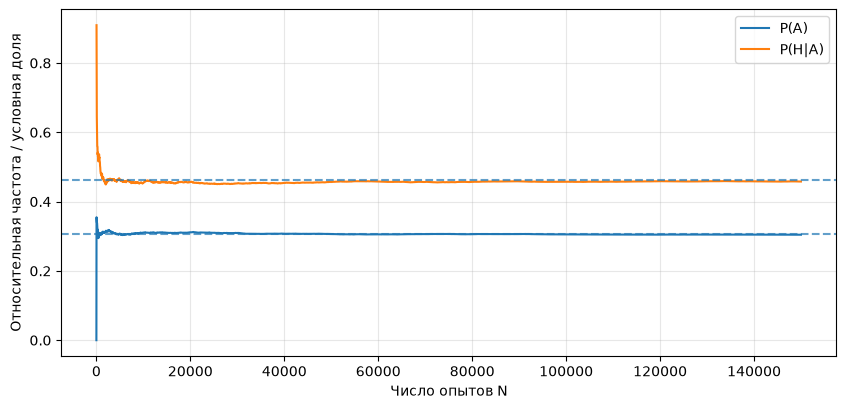

In [14]:
# 4.14
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(414)
N = 150_000
W1 = rng.binomial(3, 0.8, size=N)
W2 = rng.binomial(4, 0.7, size=N)
index = rng.integers(0, 17, size=N)
H = index < 6
A = np.where(H, index < W1, index-6 < W2)
HA = A & H
pA = (3*0.8+4*0.7)/17
pHA = (3*0.8)/(3*0.8+4*0.7)
print(f'1) P(A) = {pA:.8f}; эксперимент = {A.mean():.8f}')
print(f'2) P(H|A) = {pHA:.8f}; эксперимент = {HA.sum()/A.sum():.8f}')
n = np.arange(1, N+1)
cum_A = A.cumsum()
conditional = np.divide(HA.cumsum(), cum_A, out=np.full(N, np.nan), where=cum_A>0)
plt.figure(figsize=(10,4.5))
plt.plot(n[::30], (cum_A/n)[::30], label='P(A)')
plt.plot(n[::30], conditional[::30], label='P(H|A)')
plt.axhline(pA, linestyle='--', alpha=.7)
plt.axhline(pHA, linestyle='--', alpha=.7)
plt.xlabel('Число опытов N')
plt.ylabel('Относительная частота / условная доля')
plt.legend()
plt.grid(alpha=.3)
plt.show()

P(A) ≈ 0.367080 (до одного знака: 0.4)
P(A|B) ≈ 0.637225 (до одного знака: 0.6)


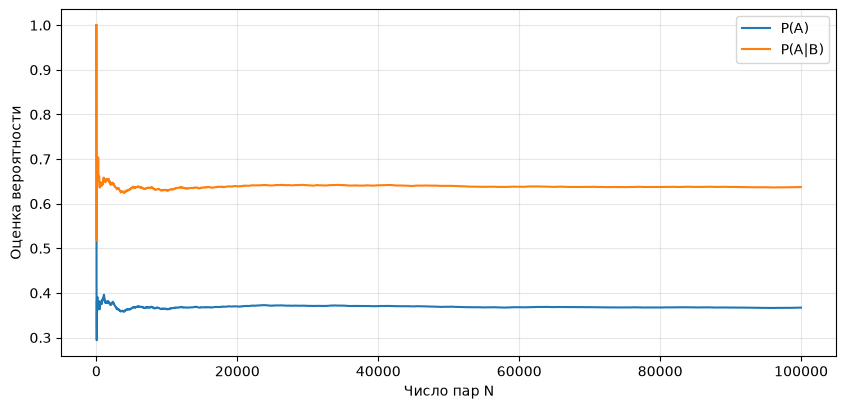

In [15]:
# 4.15
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(415)
N = 100_000
x1 = rng.uniform(-20, 20, N)
y1 = rng.uniform(-8, 8, N)
x2 = rng.uniform(-20, 20, N)
y2 = rng.uniform(-8, 8, N)
A = np.hypot(x1-x2, y1-y2) < 11
B = abs(x1-x2) < 14
AB = A & B
pA = A.mean()
pCond = AB.sum()/B.sum()
print(f'P(A) ≈ {pA:.6f} (до одного знака: {pA:.1f})')
print(f'P(A|B) ≈ {pCond:.6f} (до одного знака: {pCond:.1f})')
n = np.arange(1, N+1)
cond = np.divide(AB.cumsum(), B.cumsum(), out=np.full(N,np.nan), where=B.cumsum()>0)
plt.figure(figsize=(10,4.5))
plt.plot(n[::25], (A.cumsum()/n)[::25], label='P(A)')
plt.plot(n[::25], cond[::25], label='P(A|B)')
plt.xlabel('Число пар N')
plt.ylabel('Оценка вероятности')
plt.legend()
plt.grid(alpha=.3)
plt.show()

B: обе координаты первой точки положительны, обе координаты второй отрицательны.
P(A) ≈ 0.348300; округление до одного знака: 0.3
P(A|B) ≈ 0.071268; округление до одного знака: 0.1


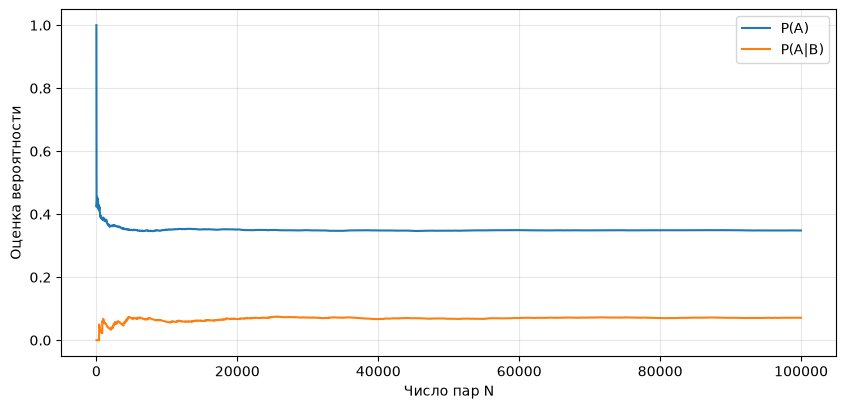

In [16]:
# 4.16
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(416)
N = 100_000
rho1 = np.sqrt(rng.random(N))
rho2 = np.sqrt(rng.random(N))
theta1 = rng.uniform(0, 2*np.pi, N)
theta2 = rng.uniform(0, 2*np.pi, N)
x1 = 23*rho1*np.cos(theta1)
y1 = 6*rho1*np.sin(theta1)
x2 = 23*rho2*np.cos(theta2)
y2 = 6*rho2*np.sin(theta2)
A = np.hypot(x1-x2, y1-y2) < 9.2
B = (x1>0) & (y1>0) & (x2<0) & (y2<0)
AB = A & B
pA = A.mean()
pCond = AB.sum()/B.sum()
print('B: обе координаты первой точки положительны, обе координаты второй отрицательны.')
print(f'P(A) ≈ {pA:.6f}; округление до одного знака: {pA:.1f}')
print(f'P(A|B) ≈ {pCond:.6f}; округление до одного знака: {pCond:.1f}')
n = np.arange(1, N+1)
conditional = np.divide(AB.cumsum(), B.cumsum(), out=np.full(N,np.nan), where=B.cumsum()>0)
plt.figure(figsize=(10,4.5))
plt.plot(n[::25], (A.cumsum()/n)[::25], label='P(A)')
plt.plot(n[::25], conditional[::25], label='P(A|B)')
plt.xlabel('Число пар N')
plt.ylabel('Оценка вероятности')
plt.legend()
plt.grid(alpha=.3)
plt.show()

P(R|T) ≈ 0.114430
P(S|T) ≈ 0.653130


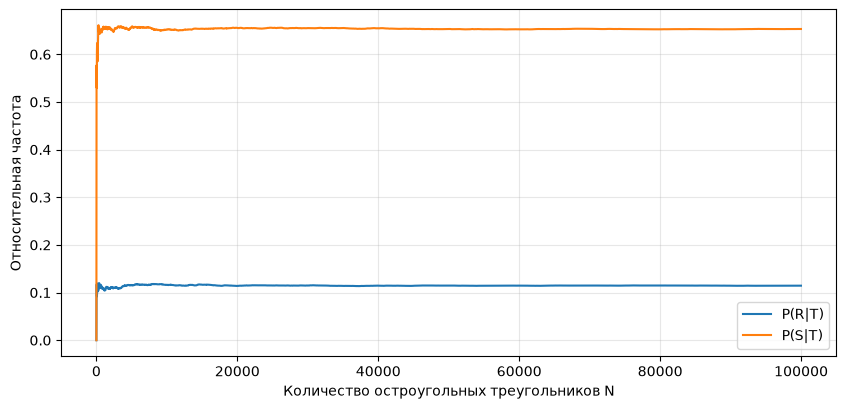

In [17]:
# 4.17
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(417)
N = 100_000
mins, maxs = [], []
count = 0
while count < N:
    points = rng.random((130_000, 3, 3))
    AB2 = np.sum((points[:, 0]-points[:, 1])**2, axis=1)
    AC2 = np.sum((points[:, 0]-points[:, 2])**2, axis=1)
    BC2 = np.sum((points[:, 1]-points[:, 2])**2, axis=1)
    acute = ((AB2+AC2 > BC2) & (AB2+BC2 > AC2) & (AC2+BC2 > AB2))
    u = AB2[acute]
    v = AC2[acute]
    w = BC2[acute]
    cosA = np.clip((u+v-w)/(2*np.sqrt(u*v)), -1, 1)
    cosB = np.clip((u+w-v)/(2*np.sqrt(u*w)), -1, 1)
    cosC = np.clip((v+w-u)/(2*np.sqrt(v*w)), -1, 1)
    angles = np.rad2deg(np.arccos(np.stack((cosA, cosB, cosC), axis=1)))
    mins.append(angles.min(axis=1))
    maxs.append(angles.max(axis=1))
    count += len(angles)
minangles = np.concatenate(mins)[:N]
maxangles = np.concatenate(maxs)[:N]
R = minangles < 26.7
S = maxangles < 81.9
print(f'P(R|T) ≈ {R.mean():.6f}')
print(f'P(S|T) ≈ {S.mean():.6f}')
n = np.arange(1, N+1)
plt.figure(figsize=(10, 4.5))
plt.plot(n[::25], (R.cumsum()/n)[::25], label='P(R|T)')
plt.plot(n[::25], (S.cumsum()/n)[::25], label='P(S|T)')
plt.xlabel('Количество остроугольных треугольников N')
plt.ylabel('Относительная частота')
plt.legend()
plt.grid(alpha=.3)
plt.show()